<a href="https://colab.research.google.com/github/sabbirpuspo/PGCB-Demand-Aware-Smart-Grid-Optimization/blob/main/PGCB__Fairness_Robustness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PGCB__Fairness_Robustness
### Matched-budget optimization, risk assessment and paired statistical analysis

**Working paper:** *An Intelligent Demand-Aware Optimization Framework for Peak Load Management and Load-Shedding Mitigation in Smart Grids*

**Main question.** The Phase 3 uncertainty-water-filling scheduler shifted more daily energy than the uncertainty-matched linear-programming (LP) method. Could its reported benefit come from using a larger movement budget? This notebook answers that question by adding **two LP controls with the same hourly uncertainty-adjusted shift caps and maximum movement budget, plus a third LP that matches the exact moved MWh while keeping the candidate's source/destination hours fixed**. It then measures realized peak demand, negative outcomes, ex-post cap violations, and paired day-level differences.

**Inputs.** Reuses the complete CSV outputs from the Phase 3 Colab notebook in `MyDrive/PGCB_Demand_Optimization/runs/phase3_*/`. **Run Phase 3 first.** No new dataset download is required, and no previously saved results are overwritten. Phase 4 copies only reproducibility metadata, not the raw UCI workbook.

**Scientific limits.** This is an *exploratory retrospective simulation*, not a measured demand-response intervention. The hourly PGCB records do not report customer-level controllable consumption; 5%, 10%, and 15% are hypothetical flexibility assumptions. This experiment does **not** demonstrate verified electricity savings, carbon reduction, reduced real-world load shedding, or a novel optimizer. The algorithm and 2023 outcome have been examined in earlier phases, so **2023 is not an untouched confirmatory test period**.

**Comparisons.** The principal comparison is `UncertaintyWaterfill` versus `BudgetMatchedRobustLP`: both use the **same** forecast, upper error envelope, conservative hourly limits, and maximum daily shift budget. `BudgetMatchedNominalLP` uses the identical feasible set but optimizes the nominal forecast instead of the upper envelope. `SignedSupportExactMWhLP` uses the same caps and exactly the candidate's moved MWh, but restricts which hours donate and receive energy to match the candidate. Original Phase 3 baselines appear for context only; they do **not** share identical constraints or movement budgets.

**Data and research context.** UCI PGCB dataset 1175, DOI https://doi.org/10.24432/C59P6V (CC BY 4.0). Relevant literature includes [Li et al., *Electric Power Systems Research* (2024)](https://doi.org/10.1016/j.epsr.2024.110326) and [Rafayal et al., *Journal of Building Engineering* (2024)](https://doi.org/10.1016/j.jobe.2024.109163). These motivate comparison, not a claim of novelty.

**Instructions.** Open in Google Colab, choose **Runtime → Run all**, authorize Google Drive, and inspect the final result table. A CPU runtime is enough. Each code cell is preceded by a text explanation.

## 1. Import the scientific libraries

We use NumPy and pandas for replaying the saved schedules, SciPy HiGHS for linear programming, and Matplotlib for reproducible figures. No GPU training is required. This phase deliberately reuses forecasts already produced in Phase 3 rather than fitting another forecasting model.

In [ ]:
import hashlib
import json
import os
import platform
import sys
import time
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import linprog

IS_COLAB = 'google.colab' in sys.modules
np.set_printoptions(precision=3, suppress=True)
print('Execution:', 'Google Colab' if IS_COLAB else 'local Python')
print('Python:', platform.python_version(), '| NumPy:', np.__version__)
print('Pandas:', pd.__version__, '| SciPy:', scipy.__version__)

Execution: Google Colab
Python: 3.13.16 | NumPy: 2.4.6
Pandas: 2.2.3 | SciPy: 1.16.3


## 2. Configure experiment paths and fixed settings

The notebook selects the most recent *complete* Phase 3 run by default. To reproduce a particular published result, set `PHASE3_RUN_ID` to its explicit folder name. In Google Colab, the results are saved to the same project folder in Drive, under a new timestamped `phase4_*` directory. For local verification, `PGCB_PROJECT_DIR` can point to the project directory.

In [ ]:
USE_GOOGLE_DRIVE = True
PHASE3_RUN_ID = None  # Replace with 'phase3_YYYYMMDDTHHMMSSZ_suffix' to pin a run
RANDOM_SEED = 20261107
BOOTSTRAP_REPETITIONS = 2000
LP_PEAK_TOLERANCE_MW = 0.05  # Tie-break allows this deviation from the minimum proxy peak
EXPECTED_ALPHAS = (0.05, 0.10, 0.15)

if IS_COLAB and USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/PGCB_Demand_Optimization')
elif IS_COLAB:
    PROJECT_DIR = Path('/content/PGCB_Demand_Optimization')
else:
    PROJECT_DIR = Path(os.environ.get('PGCB_PROJECT_DIR', '/mnt/data/PGCB_Demand_Optimization'))

RUNS_DIR = PROJECT_DIR / 'runs'
RUN_ID = 'phase4_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:6]
OUT_DIR = RUNS_DIR / RUN_ID
OUT_DIR.mkdir(parents=True, exist_ok=False)
print('Phase 4 run ID:', RUN_ID)
print('Results folder:', OUT_DIR)

Mounted at /content/drive
Phase 4 run ID: phase4_20261107T090923Z_79faff
Results folder: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/phase4_20261107T090923Z_79faff


## 3. Locate the saved Phase 3 experiment

We require the **hourly schedules**, **daily results**, **error margins**, and **protocol** from one and the same Phase 3 run. The notebook verifies their existence before proceeding. If you have several Phase 3 folders, you may pin one by setting the folder name in Section 2 rather than combining files from different runs.

In [ ]:
REQUIRED_INPUTS = (
    'phase3_hourly_schedules_2023.csv',
    'phase3_daily_results_2023.csv',
    'error_margins_2022_H2.csv',
    'phase3_protocol.json',
)

if PHASE3_RUN_ID is not None:
    INPUT_DIR = RUNS_DIR / PHASE3_RUN_ID
    if not all((INPUT_DIR / name).is_file() for name in REQUIRED_INPUTS):
        raise FileNotFoundError(f'Pinned Phase 3 run lacks required files: {INPUT_DIR}')
else:
    choices = sorted(
        (path for path in RUNS_DIR.glob('phase3_*')
         if path.is_dir() and all((path / name).is_file() for name in REQUIRED_INPUTS)),
        key=lambda path: path.name, reverse=True,
    )
    if not choices:
        raise FileNotFoundError(
            'No complete Phase 3 run found. Execute PGCB_Uncertainty_Aware_Optimization.ipynb first.'
        )
    INPUT_DIR = choices[0]

input_hashes = {
    name: hashlib.sha256((INPUT_DIR / name).read_bytes()).hexdigest()
    for name in REQUIRED_INPUTS
}
print('Using Phase 3 run:', INPUT_DIR.name)
print('Required source files:', *REQUIRED_INPUTS, sep='\n  ')

Using Phase 3 run: phase3_20261107T085050Z_d0dbce
Required source files:
  phase3_hourly_schedules_2023.csv
  phase3_daily_results_2023.csv
  error_margins_2022_H2.csv
  phase3_protocol.json


## 4. Load the exact Phase 3 output and validate its structure

The hourly source contains the recorded demand, the day-ahead Ridge forecast, and the shift chosen **before** the actual day. We check dates, per-day hour coverage, method labels, energy neutrality and numerical agreement between the saved daily and hourly tables. The input protocol must describe the Ridge 2023 experiment. The source files are read-only.

In [ ]:
hourly_input = pd.read_csv(INPUT_DIR / 'phase3_hourly_schedules_2023.csv')
daily_input = pd.read_csv(INPUT_DIR / 'phase3_daily_results_2023.csv')
margins = pd.read_csv(INPUT_DIR / 'error_margins_2022_H2.csv').set_index('hour').sort_index()
protocol_input = json.loads((INPUT_DIR / 'phase3_protocol.json').read_text())

assert protocol_input['forecast_model']['name'] == 'Ridge'
assert protocol_input['periods']['exploratory_optimization_evaluation'].startswith('2023')
assert np.array_equal(margins.index.to_numpy(), np.arange(24))
assert hourly_input.groupby(['date', 'alpha', 'method']).size().eq(24).all()
assert not hourly_input.duplicated(['date', 'alpha', 'method', 'hour']).any()
assert not daily_input.duplicated(['date', 'alpha', 'method']).any()
assert set(np.round(hourly_input['alpha'].unique(), 4)) == set(EXPECTED_ALPHAS)
assert hourly_input['date'].str.startswith('2023-').all()
assert hourly_input['method'].nunique() == 5

sources = daily_input[['date','alpha','method','peak_reduction_pct']].merge(
    hourly_input.groupby(['date','alpha','method'], as_index=False)
    .agg(saved_movement_mwh=('shift_mw', lambda v: np.abs(v).sum() / 2)),
    on=['date','alpha','method'], validate='one_to_one'
)
assert len(sources) == len(daily_input)
assert sources['saved_movement_mwh'].notna().all()
assert hourly_input.groupby(['date','alpha','method'])['shift_mw'].sum().abs().max() < 1e-3
assert daily_input['date'].nunique() == protocol_input['n_evaluated_2023_days']

UNDER = margins['underprediction_margin_mw'].to_numpy(dtype=float)
OVER = margins['overprediction_margin_mw'].to_numpy(dtype=float)
assert (UNDER >= 0).all() and (OVER >= 0).all()
print('Eligible 2023 days:', daily_input.date.nunique())
print('Hourly input rows:', len(hourly_input), '| Original day-method rows:', len(daily_input))
print('UCI original SHA256:', protocol_input['dataset']['sha256'])

Eligible 2023 days: 274
Hourly input rows: 98640 | Original day-method rows: 4110
UCI original SHA256: cd10a95b98033594b70ff176d69e9feaa2ade5f43b8ae4e5640a0f9deabc9da1


## 5. Reconstruct the candidate’s decision limits

The candidate from Phase 3 used a conservative lower-demand estimate to choose how much load could be moved in each hour. For forecast \(\hat d_t\), overprediction margin \(v_t\), and assumed flexibility \(\alpha\), its scheduling cap is

\[
 c_t = \alpha\,\max(0,\hat d_t-v_t)\, g, \qquad
 g = \frac{\max_t\hat d_t-\min_t\hat d_t}{\max_t\hat d_t-\min_t\hat d_t+\operatorname{mean}(u_t+v_t)}.
\]

Here \(u_t\) is the underprediction margin. We independently reconstruct these caps and confirm that the stored candidate schedule obeyed them. **These are forecast-time planning caps, not proven actual customer flexibility.**

In [ ]:
def conservative_caps(predicted, alpha, under, over):
    prediction = np.asarray(predicted, dtype=float)
    upward = np.asarray(under, dtype=float)
    downward = np.asarray(over, dtype=float)
    spread = float(np.ptp(prediction))
    uncertainty = float(np.mean(upward + downward))
    gate = spread / (spread + uncertainty + 1e-12)
    caps = alpha * np.maximum(prediction - downward, 0.0) * gate
    return caps, gate


def candidate_movement(shift_mw):
    return float(np.abs(np.asarray(shift_mw, dtype=float)).sum() / 2.0)

example = (hourly_input.loc[hourly_input.method.eq('UncertaintyWaterfill')
          & hourly_input.alpha.eq(0.10)].sort_values(['date','hour']).iloc[:24])
example_caps, example_gate = conservative_caps(
    example.ridge_forecast_mw.to_numpy(), 0.10, UNDER, OVER)
assert np.all(np.abs(example.shift_mw.to_numpy()) <= example_caps + 1e-4)
print('Example 2023 candidate planning gate:', round(example_gate, 4))
print('Example maximum allowed hourly shift (MW):', round(example_caps.max(), 2))

Example 2023 candidate planning gate: 0.723
Example maximum allowed hourly shift (MW): 660.18


## 6. Define the equal-budget LP comparator

This is our main fairness check. Let \(x_t\) be the shift selected for hour \(t\), and let \(B\) be the total absolute energy moved by the existing water-filling candidate. The LP receives the *same* hourly cap \(c_t\), the *same* \(B\), and preserves daily energy:

\[
\min_{x,z}\;z,\qquad r_t+x_t\le z,\qquad
 |x_t|\le c_t,\quad \sum_t x_t=0,\quad
 \frac12\sum_t |x_t|\le B.
\]

For `BudgetMatchedRobustLP`, \(r_t=\hat d_t+u_t\); for `BudgetMatchedNominalLP`, \(r_t=\hat d_t\). The absolute-value inequalities are linearized with auxiliary variables. After finding the minimum proxy peak, a **second LP** minimizes shifted energy while retaining that peak within 0.05 MW, preventing arbitrary extra shifting when the first LP has multiple optimal answers.

**Fairness scope:** The budget is an *upper bound*, not compulsory spending. Both comparators may choose to move less energy than the candidate. This provides an equal-capability test, not a forced equal-MWh schedule.

In [ ]:
def budget_matched_lp(reference, caps, max_moved_mwh, peak_tolerance_mw=LP_PEAK_TOLERANCE_MW):
    reference = np.asarray(reference, dtype=float)
    caps = np.asarray(caps, dtype=float)
    if reference.shape != (24,) or caps.shape != (24,):
        raise ValueError('Expected 24 hourly references and 24 hourly caps.')
    if not np.isfinite(reference).all() or not np.isfinite(caps).all():
        raise ValueError('Non-finite LP inputs.')
    if (caps < 0).any() or max_moved_mwh < 0:
        raise ValueError('Negative scheduling limits are not allowed.')
    n = len(reference)
    # Variables: hourly shifts x, absolute-shift auxiliaries a, proxy peak z.
    A = np.zeros((3*n + 1, 2*n + 1))
    b = np.zeros(3*n + 1)
    for hour in range(n):
        A[hour, hour] = 1.0
        A[hour, 2*n] = -1.0
        b[hour] = -reference[hour]
        A[n+hour, hour] = 1.0
        A[n+hour, n+hour] = -1.0
        A[2*n+hour, hour] = -1.0
        A[2*n+hour, n+hour] = -1.0
    A[-1, n:2*n] = 1.0
    b[-1] = 2.0 * max_moved_mwh
    A_equal = np.zeros((1, 2*n+1))
    A_equal[0, :n] = 1.0
    bounds = [(-float(cap), float(cap)) for cap in caps]
    bounds += [(0.0, None)] * n + [(0.0, None)]

    peak_cost = np.zeros(2*n+1)
    peak_cost[-1] = 1.0
    first = linprog(peak_cost, A_ub=A, b_ub=b, A_eq=A_equal,
                    b_eq=[0.0], bounds=bounds, method='highs')
    if not first.success:
        raise RuntimeError('Primary peak-minimization LP: ' + first.message)

    # With the minimum proxy peak essentially fixed, minimize total movement.
    movement_cost = np.zeros(2*n+1)
    movement_cost[n:2*n] = 1.0
    second_bounds = bounds[:-1] + [(0.0, float(first.x[-1] + peak_tolerance_mw))]
    second = linprog(movement_cost, A_ub=A, b_ub=b, A_eq=A_equal,
                     b_eq=[0.0], bounds=second_bounds, method='highs')
    if not second.success:
        raise RuntimeError('Movement tie-break LP: ' + second.message)
    shifts = np.asarray(second.x[:n], dtype=float)
    assert abs(shifts.sum()) < 1e-4
    assert np.all(np.abs(shifts) <= caps + 1e-4)
    assert candidate_movement(shifts) <= max_moved_mwh + 1e-4
    assert np.max(reference + shifts) <= first.x[-1] + peak_tolerance_mw + 1e-3
    return shifts, float(first.x[-1])



def signed_support_exact_lp(reference, caps, original_shift):
    """Exactly match moved MWh and the signs/support chosen by the candidate.

    This is an allocation-only diagnostic: the LP may redistribute movement
    within candidate-selected donating and receiving hours, but cannot
    select new hours. It is not a globally unrestricted exact-movement LP.
    """
    reference = np.asarray(reference, dtype=float)
    caps = np.asarray(caps, dtype=float)
    original = np.asarray(original_shift, dtype=float)
    assert reference.shape == caps.shape == original.shape == (24,)
    assert abs(original.sum()) <= 1e-4
    assert np.all(np.abs(original) <= caps + 1e-4)
    budget = candidate_movement(original)
    if budget <= 1e-8:
        return np.zeros(24), float(reference.max())
    donors = original < -1e-6
    receivers = original > 1e-6
    assert donors.any() and receivers.any()
    n = len(reference)
    # Variables: n signed hourly shifts and one proxy maximum.
    A = np.zeros((n, n+1))
    A[:, :n] = np.eye(n)
    A[:, -1] = -1.0
    b = -reference
    Aeq = np.zeros((2, n+1))
    Aeq[0, :n] = 1.0
    Aeq[1, np.flatnonzero(receivers)] = 1.0
    lo_hi = []
    for hour in range(n):
        if donors[hour]:
            lo_hi.append((-float(caps[hour]), 0.0))
        elif receivers[hour]:
            lo_hi.append((0.0, float(caps[hour])))
        else:
            lo_hi.append((0.0, 0.0))
    lo_hi.append((0.0, None))
    objective = np.zeros(n+1)
    objective[-1] = 1.0
    answer = linprog(objective, A_ub=A, b_ub=b, A_eq=Aeq,
                     b_eq=[0.0, budget], bounds=lo_hi, method='highs')
    if not answer.success:
        raise RuntimeError('Exact-movement support LP: ' + answer.message)
    shifts = np.asarray(answer.x[:n], dtype=float)
    assert abs(shifts.sum()) < 1e-4
    assert abs(candidate_movement(shifts) - budget) < 1e-4
    assert np.all(np.abs(shifts) <= caps + 1e-4)
    assert np.max(reference + shifts) <= np.max(reference + original) + 1e-3
    return shifts, float(answer.x[-1])

## 7. Test the optimizer with constructed demand profiles

These tests use artificial 24-hour profiles only. They verify zero movement when the budget is zero, daily energy conservation, hourly caps, budget caps, and that the LP proxy peak is no worse than a feasible comparison schedule. Unit tests are **not** PGCB performance results.

In [ ]:
test_profile = np.array([7700 + 2400*np.exp(-((h-19)/3)**2) +
                         900*np.exp(-((h-10)/2)**2) for h in range(24)])
test_under = np.linspace(430, 650, 24)
test_over = np.linspace(350, 550, 24)
checks = 0
for alpha in EXPECTED_ALPHAS:
    caps, _ = conservative_caps(test_profile, alpha, test_under, test_over)
    for budget in [0.0, 500.0, 1800.0]:
        shifts, optimum = budget_matched_lp(test_profile + test_under, caps, budget)
        assert np.isclose(shifts.sum(), 0.0, atol=1e-5)
        assert np.all(np.abs(shifts) <= caps + 1e-5)
        assert candidate_movement(shifts) <= budget + 1e-5
        assert np.max(test_profile + test_under + shifts) <= np.max(test_profile + test_under) + 1e-3
        checks += 4
        if budget == 0.0:
            assert np.max(np.abs(shifts)) < 1e-5
            checks += 1
candidate_direction = np.zeros(24)
candidate_direction[4] = 120.0
candidate_direction[19] = -120.0
synthetic_caps = np.full(24, 300.0)
exact_delta, _ = signed_support_exact_lp(test_profile + test_under,
                                         synthetic_caps, candidate_direction)
assert np.isclose(candidate_movement(exact_delta), 120.0, atol=1e-4)
assert (exact_delta > 1e-6).sum() == 1 and (exact_delta < -1e-6).sum() == 1
checks += 2
print('Synthetic mathematical checks passed:', checks)

Synthetic mathematical checks passed: 41


## 8. Replay every original case and solve the matched controls

Each case uses one calendar day, one assumed flexibility fraction, and the forecasts and uncertainty margins archived by Phase 3. We preserve all existing methods for context, and calculate two new equal-budget LP schedules. The LP *never sees future actual demand while making its decision*; actual demand is used only afterward to score the simulated outcome. Hourly LP traces are saved for independent auditing.

In [ ]:
ORIGINAL_METHODS = ('NoAction', 'FixedRule', 'NominalLP',
                    'UncertaintyWaterfill', 'MatchedUncertaintyLP')
NEW_METHODS = ('BudgetMatchedRobustLP', 'BudgetMatchedNominalLP', 'SignedSupportExactMWhLP')
ALL_METHODS = ORIGINAL_METHODS + NEW_METHODS


def score_schedule(date, alpha, method, observed, predicted, shift, budget, runtime_ms):
    observed = np.asarray(observed, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    shift = np.asarray(shift, dtype=float)
    realized = observed + shift
    actual_caps = alpha * observed
    cap_flags = np.abs(shift) > actual_caps + 1e-4
    negative_flags = realized < -1e-4
    before = float(observed.max())
    after = float(realized.max())
    return {
        'date': date, 'alpha': float(alpha), 'method': method,
        'baseline_peak_mw': before, 'simulated_peak_mw': after,
        'peak_reduction_mw': before-after,
        'peak_reduction_pct': 100.0*(before-after)/before,
        'moved_energy_mwh': candidate_movement(shift),
        'candidate_budget_mwh': float(budget),
        'actual_cap_violation_day': int(cap_flags.any()),
        'actual_cap_violation_hours': int(cap_flags.sum()),
        'negative_simulated_day': int(negative_flags.any()),
        'worsened_peak': int(after > before + 1e-4),
        'realized_caps_feasible_day': int(not cap_flags.any() and not negative_flags.any()),
        'forecast_mae_mw': float(np.abs(observed-predicted).mean()),
        'daily_energy_error_mwh': float(shift.sum()),
        'proxy_robust_peak_mw': float(np.max(predicted+UNDER+shift)),
        'proxy_nominal_peak_mw': float(np.max(predicted+shift)),
        'runtime_ms': runtime_ms,
    }

DAILY_ROWS = []
NEW_HOURLY_ROWS = []
GROUPS = list(hourly_input.groupby(['date', 'alpha'], sort=True))
for case_index, ((date, alpha), group) in enumerate(GROUPS, start=1):
    candidate = group.loc[group.method.eq('UncertaintyWaterfill')].sort_values('hour')
    assert np.array_equal(candidate.hour.to_numpy(dtype=int), np.arange(24))
    observed = candidate.actual_mw.to_numpy(dtype=float)
    predicted = candidate.ridge_forecast_mw.to_numpy(dtype=float)
    candidate_shift = candidate.shift_mw.to_numpy(dtype=float)
    caps, gate = conservative_caps(predicted, alpha, UNDER, OVER)
    assert np.max(np.abs(candidate_shift) - caps) <= 1e-4
    budget = candidate_movement(candidate_shift)

    for name in ORIGINAL_METHODS:
        original = group.loc[group.method.eq(name)].sort_values('hour')
        assert len(original) == 24
        assert np.allclose(original.actual_mw, observed, atol=1e-6)
        assert np.allclose(original.ridge_forecast_mw, predicted, atol=1e-6)
        shifts = original.shift_mw.to_numpy(dtype=float)
        DAILY_ROWS.append(score_schedule(date, alpha, name, observed, predicted, shifts, budget, np.nan))

    for name, reference in (
        ('BudgetMatchedRobustLP', predicted + UNDER),
        ('BudgetMatchedNominalLP', predicted),
        ('SignedSupportExactMWhLP', predicted + UNDER),
    ):
        tic = time.perf_counter()
        if name == 'SignedSupportExactMWhLP':
            shifts, ideal_peak = signed_support_exact_lp(reference, caps, candidate_shift)
        else:
            shifts, ideal_peak = budget_matched_lp(reference, caps, budget)
        elapsed_ms = 1000.0 * (time.perf_counter() - tic)
        daily_row = score_schedule(date, alpha, name, observed, predicted,
                                  shifts, budget, elapsed_ms)
        daily_row['optimum_proxy_peak_mw'] = ideal_peak
        DAILY_ROWS.append(daily_row)
        for hour in range(24):
            NEW_HOURLY_ROWS.append({
                'date': date, 'alpha': alpha, 'hour': hour, 'method': name,
                'actual_mw': observed[hour], 'forecast_mw': predicted[hour],
                'underprediction_margin_mw': UNDER[hour],
                'overprediction_margin_mw': OVER[hour],
                'planning_shift_cap_mw': caps[hour],
                'shift_mw': shifts[hour], 'simulated_mw': observed[hour]+shifts[hour],
                'candidate_budget_mwh': budget,
            })
    if case_index % 150 == 0:
        print(f'Processed {case_index} / {len(GROUPS)} day-flexibility scenarios')

DAILY = pd.DataFrame(DAILY_ROWS)
NEW_HOURLY = pd.DataFrame(NEW_HOURLY_ROWS)
DAILY.to_csv(OUT_DIR / 'phase4_daily_results_2023.csv', index=False)
NEW_HOURLY.to_csv(OUT_DIR / 'phase4_equal_budget_hourly_lp_2023.csv', index=False)
print('Day-method records:', len(DAILY))
print('New hourly LP traces:', len(NEW_HOURLY))

Processed 150 / 822 day-flexibility scenarios
Processed 300 / 822 day-flexibility scenarios
Processed 450 / 822 day-flexibility scenarios
Processed 600 / 822 day-flexibility scenarios
Processed 750 / 822 day-flexibility scenarios
Day-method records: 6576
New hourly LP traces: 59184


## 9. Check replay accuracy and mathematical invariants

Before interpreting the new results, compare the replayed original methods with the Phase 3 daily files to rule out accidental changes. Check energy neutrality, identical day coverage, the candidate-based movement budget, and dominance of the LP *on the proxy objective it actually optimizes*. That dominance does **not** guarantee better realized peaks, because actual demand differs from forecasts.

In [ ]:
replayed = DAILY.loc[DAILY.method.isin(ORIGINAL_METHODS)]
paired_source = replayed[['date','alpha','method','peak_reduction_pct','moved_energy_mwh']].merge(
    daily_input[['date','alpha','method','peak_reduction_pct','moved_energy_mwh']],
    on=['date','alpha','method'], suffixes=('_replay','_phase3'), validate='one_to_one')
assert len(paired_source) == len(daily_input)
assert np.allclose(paired_source.peak_reduction_pct_replay,
                   paired_source.peak_reduction_pct_phase3, atol=1e-6)
assert np.allclose(paired_source.moved_energy_mwh_replay,
                   paired_source.moved_energy_mwh_phase3, atol=1e-6)
assert DAILY.groupby(['method','alpha']).date.nunique().eq(daily_input.date.nunique()).all()
assert DAILY.daily_energy_error_mwh.abs().max() <= 1e-3
assert DAILY.loc[DAILY.method.isin(NEW_METHODS), 'moved_energy_mwh'].le(
    DAILY.loc[DAILY.method.isin(NEW_METHODS), 'candidate_budget_mwh'] + 1e-3).all()

comparison = DAILY.pivot_table(index=['date','alpha'], columns='method',
                               values=['proxy_robust_peak_mw','proxy_nominal_peak_mw'])
robust_gap = (comparison[('proxy_robust_peak_mw','BudgetMatchedRobustLP')]
              - comparison[('proxy_robust_peak_mw','UncertaintyWaterfill')])
nominal_gap = (comparison[('proxy_nominal_peak_mw','BudgetMatchedNominalLP')]
               - comparison[('proxy_nominal_peak_mw','UncertaintyWaterfill')])
assert robust_gap.max() <= LP_PEAK_TOLERANCE_MW + 1e-2
assert nominal_gap.max() <= LP_PEAK_TOLERANCE_MW + 1e-2
movements = DAILY.pivot(index=['date','alpha'],columns='method',values='moved_energy_mwh')
assert np.allclose(movements['SignedSupportExactMWhLP'],
                   movements['UncertaintyWaterfill'], atol=1e-4)
assert not DAILY.duplicated(['date','alpha','method']).any()
print('Original Phase 3 results reproduced:', len(paired_source), 'day-method rows')
print('Max absolute daily energy-balance error (MWh):',
      round(DAILY.daily_energy_error_mwh.abs().max(), 9))
print('Max LP minus candidate robust-proxy peak (MW):', round(robust_gap.max(), 4))
print('Max LP minus candidate nominal-proxy peak (MW):', round(nominal_gap.max(), 4))

Original Phase 3 results reproduced: 4110 day-method rows
Max absolute daily energy-balance error (MWh): 0.0
Max LP minus candidate robust-proxy peak (MW): 0.05
Max LP minus candidate nominal-proxy peak (MW): 0.05


## 10. Summarize the benefit-risk trade-offs

Peak reduction alone can hide important operational assumptions. For every method, report the mean and median improvement, share of worse-peak days, number of realized cap violations, and average movement in MWh. The realized cap test uses `alpha × actual demand` *after the day occurred*, so it is an evaluation diagnostic—not information available to the scheduler.

In [ ]:
SUMMARY = (DAILY.groupby(['method','alpha'], as_index=False)
    .agg(days=('date','nunique'),
         mean_peak_reduction_pct=('peak_reduction_pct','mean'),
         median_peak_reduction_pct=('peak_reduction_pct','median'),
         mean_peak_reduction_mw=('peak_reduction_mw','mean'),
         worsened_days_pct=('worsened_peak',lambda x: 100*x.mean()),
         actual_cap_violation_days_pct=('actual_cap_violation_day',lambda x:100*x.mean()),
         negative_demand_days_pct=('negative_simulated_day',lambda x:100*x.mean()),
         feasible_days_pct=('realized_caps_feasible_day',lambda x:100*x.mean()),
         mean_movement_mwh=('moved_energy_mwh','mean'),
         mean_candidate_budget_mwh=('candidate_budget_mwh','mean'),
         mean_forecast_mae_mw=('forecast_mae_mw','mean')))
SUMMARY.to_csv(OUT_DIR / 'phase4_summary_2023.csv', index=False)
print(SUMMARY.loc[SUMMARY.alpha.eq(0.15), [
    'method','days','mean_peak_reduction_pct','worsened_days_pct',
    'actual_cap_violation_days_pct','mean_movement_mwh'
]].round(3).to_string(index=False))

                 method  days  mean_peak_reduction_pct  worsened_days_pct  actual_cap_violation_days_pct  mean_movement_mwh
 BudgetMatchedNominalLP   274                    5.489              9.124                          3.650           5419.187
  BudgetMatchedRobustLP   274                    5.470              9.489                          4.015           5424.254
              FixedRule   274                    4.148             22.263                         59.854           8471.864
   MatchedUncertaintyLP   274                    5.532              8.759                          4.380           5424.649
               NoAction   274                    0.000              0.000                          0.000              0.000
              NominalLP   274                    7.099              8.759                         37.956           8247.223
SignedSupportExactMWhLP   274                    5.998              8.394                          4.015           6471.634
   Uncer

## 11. Calculate paired differences and uncertainty intervals

This section makes **paired** comparisons: on each date, the candidate and the benchmark face the same historical demand and the same forecast. We calculate daily percentage-point differences and how often each method is better. For a descriptive uncertainty interval, we resample **calendar weeks** (not individual hours) 2,000 times, preserving within-week dependence. These intervals are exploratory; the same year was inspected in prior phases, and week-level bootstrap does not remove selection bias or provide a formal independent confirmation.

In [ ]:
PIVOT = DAILY.pivot(index=['date','alpha'], columns='method', values='peak_reduction_pct')
PIVOT_MOVED = DAILY.pivot(index=['date','alpha'], columns='method', values='moved_energy_mwh')
PAIRED = PIVOT.reset_index()
PAIRED['candidate_minus_matched_robust_lp_pp'] = (
    PAIRED['UncertaintyWaterfill'] - PAIRED['BudgetMatchedRobustLP'])
PAIRED['candidate_minus_matched_nominal_lp_pp'] = (
    PAIRED['UncertaintyWaterfill'] - PAIRED['BudgetMatchedNominalLP'])
PAIRED['candidate_minus_exact_support_lp_pp'] = (
    PAIRED['UncertaintyWaterfill'] - PAIRED['SignedSupportExactMWhLP'])
PAIRED['candidate_minus_old_matched_lp_pp'] = (
    PAIRED['UncertaintyWaterfill'] - PAIRED['MatchedUncertaintyLP'])
PAIRED['candidate_movement_mwh'] = PIVOT_MOVED['UncertaintyWaterfill'].to_numpy()
PAIRED['robust_lp_movement_mwh'] = PIVOT_MOVED['BudgetMatchedRobustLP'].to_numpy()
PAIRED['nominal_lp_movement_mwh'] = PIVOT_MOVED['BudgetMatchedNominalLP'].to_numpy()
PAIRED['signed_support_exact_lp_movement_mwh'] = PIVOT_MOVED['SignedSupportExactMWhLP'].to_numpy()
PAIRED.to_csv(OUT_DIR / 'phase4_paired_daily_comparisons_2023.csv', index=False)


def week_cluster_bootstrap(values, dates, repetitions=BOOTSTRAP_REPETITIONS, seed=RANDOM_SEED):
    numbers = np.asarray(values, dtype=float)
    calendar = pd.to_datetime(pd.Series(dates))
    weeks = calendar.dt.strftime('%G-W%V').to_numpy()
    unique_weeks = pd.unique(weeks)
    positions = [np.flatnonzero(weeks == w) for w in unique_weeks]
    rng = np.random.default_rng(seed)
    draws = np.empty(repetitions)
    for iteration in range(repetitions):
        sampled = rng.integers(0, len(positions), size=len(positions))
        selected = np.concatenate([positions[i] for i in sampled])
        draws[iteration] = numbers[selected].mean()
    return np.quantile(draws, [0.025, 0.975]).tolist()

PAIRED_ROWS = []
for alpha in EXPECTED_ALPHAS:
    part = PAIRED.loc[PAIRED.alpha.eq(alpha)].sort_values('date')
    for benchmark, diff_column in (
        ('BudgetMatchedRobustLP','candidate_minus_matched_robust_lp_pp'),
        ('BudgetMatchedNominalLP','candidate_minus_matched_nominal_lp_pp'),
        ('SignedSupportExactMWhLP','candidate_minus_exact_support_lp_pp'),
        ('MatchedUncertaintyLP','candidate_minus_old_matched_lp_pp'),
    ):
        differences = part[diff_column].to_numpy(dtype=float)
        ci = week_cluster_bootstrap(differences, part.date, seed=RANDOM_SEED + int(alpha*1000))
        PAIRED_ROWS.append({
            'alpha': alpha, 'candidate': 'UncertaintyWaterfill',
            'benchmark': benchmark, 'days': len(part),
            'mean_difference_pp': float(differences.mean()),
            'median_difference_pp': float(np.median(differences)),
            'candidate_better_days_pct': float(100*np.mean(differences > 1e-6)),
            'benchmark_better_days_pct': float(100*np.mean(differences < -1e-6)),
            'week_cluster_bootstrap_95ci_low_pp': float(ci[0]),
            'week_cluster_bootstrap_95ci_high_pp': float(ci[1]),
        })
PAIRED_STATS = pd.DataFrame(PAIRED_ROWS)
PAIRED_STATS.to_csv(OUT_DIR / 'phase4_paired_weekly_bootstrap.csv', index=False)
print(PAIRED_STATS.round(3).to_string(index=False))

 alpha            candidate               benchmark  days  mean_difference_pp  median_difference_pp  candidate_better_days_pct  benchmark_better_days_pct  week_cluster_bootstrap_95ci_low_pp  week_cluster_bootstrap_95ci_high_pp
  0.05 UncertaintyWaterfill   BudgetMatchedRobustLP   274               0.450                 0.226                     78.832                      1.460                               0.361                                0.533
  0.05 UncertaintyWaterfill  BudgetMatchedNominalLP   274               0.420                 0.157                     76.642                      6.569                               0.339                                0.502
  0.05 UncertaintyWaterfill SignedSupportExactMWhLP   274               0.037                 0.000                     16.058                      9.489                              -0.003                                0.074
  0.05 UncertaintyWaterfill    MatchedUncertaintyLP   274               0.351               

## 12. Inspect the worst-case days and forecast-error relationship

We retain negative outcomes in the full statistics. This diagnostic selects the five dates with the largest realized peak increases for each method and scenario, and shows how average peak change varies across forecast-error groups. The quartiles use **2023 forecast errors only for retrospective analysis**, not for scheduling decisions or parameter selection.

In [ ]:
worst_days = (DAILY.loc[DAILY.method.ne('NoAction')]
              .sort_values('peak_reduction_pct', ascending=True)
              .groupby(['method','alpha'], as_index=False).head(5))
worst_days.to_csv(OUT_DIR / 'phase4_worst_five_days.csv', index=False)

focus = DAILY.loc[DAILY.alpha.eq(0.15) & DAILY.method.isin(
    ['UncertaintyWaterfill','BudgetMatchedRobustLP','BudgetMatchedNominalLP','SignedSupportExactMWhLP'])].copy()
mae_by_date = focus.drop_duplicates('date').set_index('date')['forecast_mae_mw']
q = pd.qcut(mae_by_date.rank(method='first'), q=4, labels=['Q1','Q2','Q3','Q4'])
focus['forecast_error_quartile'] = focus.date.map(q.to_dict())
ERROR_GROUPS = (focus.groupby(['method','forecast_error_quartile'], as_index=False)
                .agg(n_days=('date','nunique'),
                     average_peak_reduction_pct=('peak_reduction_pct','mean'),
                     worsened_pct=('worsened_peak',lambda x:100*x.mean())))
ERROR_GROUPS.to_csv(OUT_DIR / 'phase4_forecast_error_quartiles.csv', index=False)
print('Worst realized peak increase across all examined methods:',
      round(worst_days.peak_reduction_pct.min(), 2), '%')
print('Error-quartile diagnostic saved.')

Worst realized peak increase across all examined methods: -11.81 %
Error-quartile diagnostic saved.


## 13. Draw the key fairness and robustness figures

The figures compare realized peak outcomes across flexibility assumptions, the average **actual** movement used, and how many days produced worse peaks or cap violations. These outputs are exploratory diagnostics, not figures proving a newly invented algorithm or real-world load-shedding mitigation.

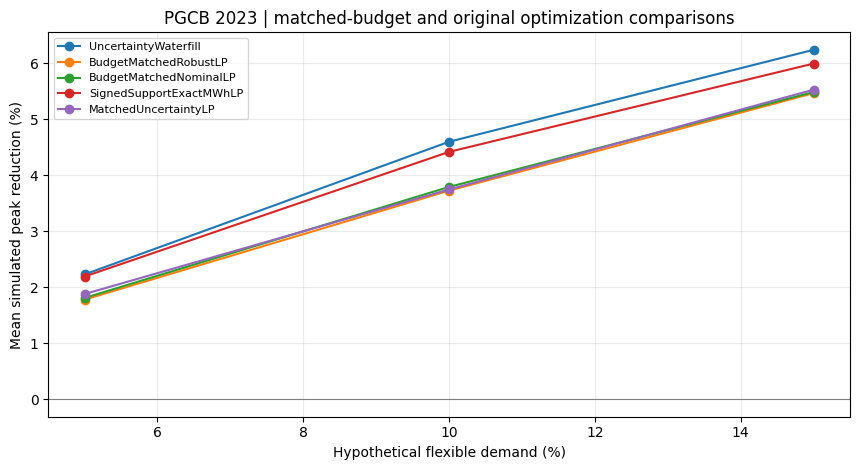

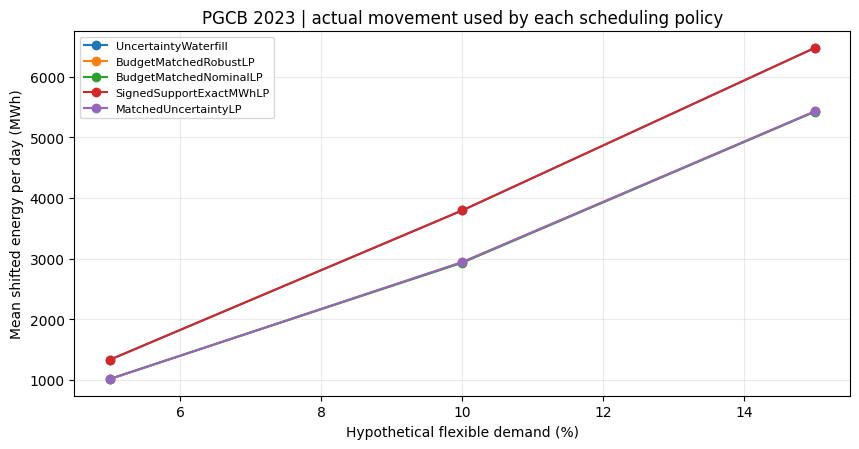

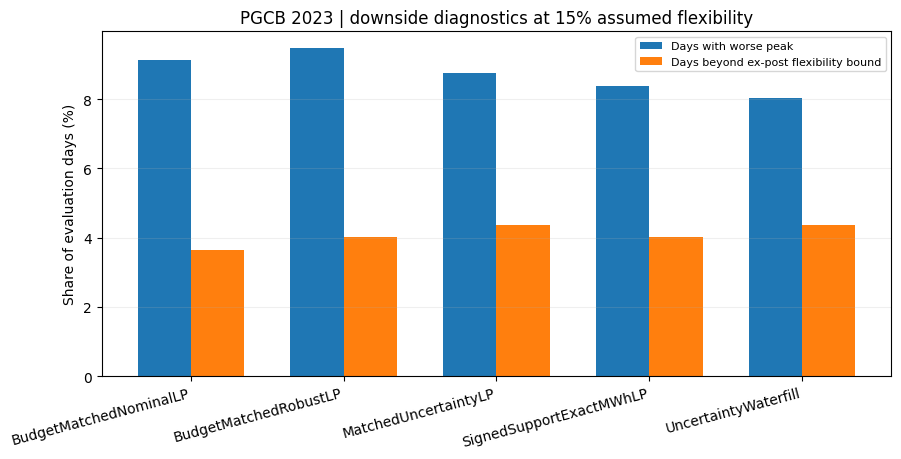

In [ ]:
PLOT_METHODS = ['UncertaintyWaterfill', 'BudgetMatchedRobustLP',
                'BudgetMatchedNominalLP', 'SignedSupportExactMWhLP', 'MatchedUncertaintyLP']

fig, ax = plt.subplots(figsize=(8.7, 4.8))
for name in PLOT_METHODS:
    curve = SUMMARY.loc[SUMMARY.method.eq(name)].sort_values('alpha')
    ax.plot(curve.alpha*100, curve.mean_peak_reduction_pct, 'o-', label=name)
ax.axhline(0, linewidth=0.8, color='gray')
ax.set(xlabel='Hypothetical flexible demand (%)',
       ylabel='Mean simulated peak reduction (%)',
       title='PGCB 2023 | matched-budget and original optimization comparisons')
ax.grid(alpha=0.25); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / 'phase4_peak_reduction_comparison.png', dpi=600)
plt.show()

fig, ax = plt.subplots(figsize=(8.7, 4.6))
for name in PLOT_METHODS:
    curve = SUMMARY.loc[SUMMARY.method.eq(name)].sort_values('alpha')
    ax.plot(curve.alpha*100, curve.mean_movement_mwh, 'o-', label=name)
ax.set(xlabel='Hypothetical flexible demand (%)',
       ylabel='Mean shifted energy per day (MWh)',
       title='PGCB 2023 | actual movement used by each scheduling policy')
ax.grid(alpha=0.25); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / 'phase4_movement_comparison.png', dpi=600)
plt.show()

slice15 = SUMMARY.loc[SUMMARY.alpha.eq(0.15) & SUMMARY.method.isin(PLOT_METHODS)]
x = np.arange(len(slice15)); width=0.35
fig, ax = plt.subplots(figsize=(9.2, 4.7))
ax.bar(x-width/2, slice15.worsened_days_pct, width, label='Days with worse peak')
ax.bar(x+width/2, slice15.actual_cap_violation_days_pct, width,
       label='Days beyond ex-post flexibility bound')
ax.set_xticks(x, slice15.method, rotation=15, ha='right')
ax.set(ylabel='Share of evaluation days (%)',
       title='PGCB 2023 | downside diagnostics at 15% assumed flexibility')
ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig(OUT_DIR / 'phase4_downside_risk.png', dpi=600)
plt.show()

## 14. Save the reproducibility record and complete output archive

This cell preserves the exact input Phase 3 folder, checksums, software versions, mathematical constraints, bootstrap settings, and research limitations. It creates a ZIP of **Phase 4 output files only**. The ZIP is useful for GitHub or coauthor review; keep the original Phase 3 run and the source PGCB data citation separately.

In [ ]:
MANIFEST = {
    'research_title': 'An Intelligent Demand-Aware Optimization Framework for Peak Load Management and Load-Shedding Mitigation in Smart Grids',
    'phase': 'Phase 4 exploratory fairness and robustness analysis',
    'phase4_run_id': RUN_ID,
    'input_phase3_run_id': INPUT_DIR.name,
    'input_csv_sha256': input_hashes,
    'original_uci_dataset': {
        'doi': '10.24432/C59P6V',
        'sha256': protocol_input['dataset']['sha256'],
        'license': 'CC BY 4.0',
    },
    'evaluation': {
        'period': '2023 exploratory; exposed in prior phases (NOT independent confirmatory test)',
        'n_days': int(DAILY.date.nunique()),
        'hypothetical_flexible_demand_fractions': list(EXPECTED_ALPHAS),
        'primary_comparison': ['UncertaintyWaterfill','BudgetMatchedRobustLP'],
        'additional_exact_movement_comparator': 'SignedSupportExactMWhLP (candidate-selected donor/receiver hours)',
        'matched_hourly_caps': True,
        'matched_maximum_daily_movement_budget': True,
        'movement_need_not_equal_budget': True,
        'signed_support_comparator_matches_exact_movement': True,
        'same_forecast_and_2022_margins': True,
        'mathematical_peak_tolerance_mw': LP_PEAK_TOLERANCE_MW,
        'bootstrap_unit': 'calendar weeks; exploratory weekly cluster resampling',
        'bootstrap_repetitions': BOOTSTRAP_REPETITIONS,
        'random_seed': RANDOM_SEED,
    },
    'source_protocol_phase3': protocol_input,
    'software': {'python': platform.python_version(), 'numpy': np.__version__,
                 'pandas': pd.__version__, 'scipy': scipy.__version__},
    'limitations': [
        'No customer-level flexibility observed in PGCB; all flexibility assumptions are hypothetical.',
        'Capacity, network losses, electricity costs and actual dispatch constraints are unavailable.',
        'Retrospective cap violations flag modeled infeasibility; no hindsight repair is applied.',
        'The budget-matched LP optimizes forecast-based upper or nominal demand, not the realized load.',
        'An LP can be optimal for its proxy objective but not for unobserved future demand.',
        'The candidate budget is selected by the original candidate at forecast time; comparators receive at most that budget.',
        'The exact-movement LP is restricted to candidate-selected source/sink hours; it is an allocation diagnostic, not unrestricted global optimization.',
        'Peak reduction on a day with cap violations cannot be claimed feasible.',
        'No real load-shedding, CO2 or electricity-bill improvement is established.',
        '2023 outcomes have already influenced exploratory research; no independent inference of novelty or generalization.',
        'The original water-filling concept is established in optimization research; novelty remains unproved.',
    ],
}
(OUT_DIR / 'phase4_protocol.json').write_text(json.dumps(MANIFEST, indent=2))
ZIP_PATH = OUT_DIR / 'phase4_outputs.zip'
with zipfile.ZipFile(ZIP_PATH, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for item in sorted(OUT_DIR.iterdir()):
        if item.is_file() and item != ZIP_PATH:
            archive.write(item, arcname=item.name)
required_outputs = (
    'phase4_daily_results_2023.csv',
    'phase4_equal_budget_hourly_lp_2023.csv',
    'phase4_summary_2023.csv',
    'phase4_paired_daily_comparisons_2023.csv',
    'phase4_paired_weekly_bootstrap.csv',
    'phase4_protocol.json', 'phase4_outputs.zip',
)
assert all((OUT_DIR / name).is_file() for name in required_outputs)
print('Phase 4 completed successfully.')
print('Input Phase 3 run:', INPUT_DIR.name)
print('Output directory:', OUT_DIR)
print('Files saved:', len(list(OUT_DIR.iterdir())))
print('Next research decision: use the matched-budget evidence to decide whether the candidate needs a new mechanism before final evaluation.')

Phase 4 completed successfully.
Input Phase 3 run: phase3_20261107T085050Z_d0dbce
Output directory: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/phase4_20261107T090923Z_79faff
Files saved: 12
Next research decision: use the matched-budget evidence to decide whether the candidate needs a new mechanism before final evaluation.
